# Interpolation with `scipy.interpolate` (1-D)

Given data $(x_i, y_i)$, build a function $p$ with $p(x_i) = y_i$ and evaluate it **between** the data points.
Every method below is used the same way: **build once**, then **evaluate** at as many new points as you like.

| method | call | continuous | local? | overshoot? |
|---|---|---|---|---|
| linear | `np.interp(xnew, x, y)` | $p$ | yes | never |
| cubic spline | `si.CubicSpline(x, y)` | $p, p', p''$ | no | can overshoot |
| Akima | `si.Akima1DInterpolator(x, y)` | $p, p'$ | yes | small, sometimes |
| modified Akima | `si.Akima1DInterpolator(x, y, method="makima")` | $p, p'$ | yes | small, rarely |
| PCHIP | `si.PchipInterpolator(x, y)` | $p, p'$ | yes | never between monotone data |

More details: SciPy User Guide, *Interpolation → 1-D interpolation*:
<https://docs.scipy.org/doc/scipy/tutorial/interpolate/1D.html#tutorial-interpolate-1dsection>

- **Linear**: straight lines between neighbours. Simple and safe, but has corners.
- **Cubic spline**: the smoothest piecewise cubic. All slopes are solved together, so one data point affects the whole curve.
- **Akima, makima, PCHIP**: piecewise cubics whose slopes are chosen **locally** from nearby data. They give up continuity of $p''$ to avoid wiggles.
- The $x$ values must be **increasing**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate as si

## Example 1: the running example from class

Seven points that rise and then level off. We build all five interpolants and evaluate them on a fine grid.

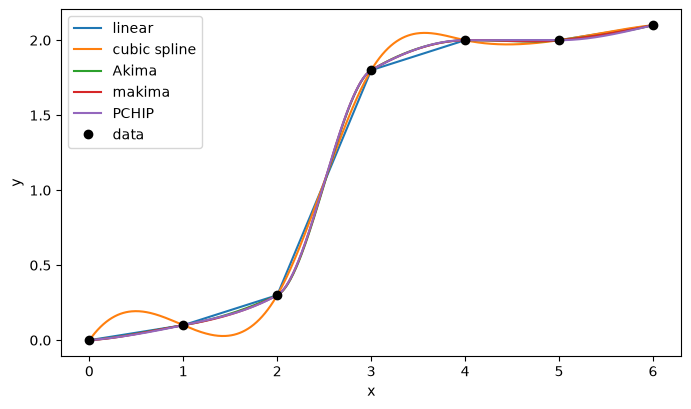

In [2]:
x = np.array([0, 1, 2, 3, 4, 5, 6.])
y = np.array([0, 0.1, 0.3, 1.8, 2.0, 2.0, 2.1])

names = ["linear", "cubic spline", "Akima", "makima", "PCHIP"]
methods = [
    lambda xn: np.interp(xn, x, y),
    si.CubicSpline(x, y),
    si.Akima1DInterpolator(x, y),
    si.Akima1DInterpolator(x, y, method="makima"),
    si.PchipInterpolator(x, y),
]

xnew = np.linspace(0, 6, 601)

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, p in zip(names, methods):
    ax.plot(xnew, p(xnew), label=name)
ax.plot(x, y, "ko", label="data")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend()
plt.show()

All five curves pass through the data. To compare them we check two things on the fine grid:

- **range**: do the values stay inside $[\min y, \max y] = [0, 2.1]$?
- **monotone**: the data never decrease, so does the curve also never decrease?

In [3]:
print(f"{'method':13s} {'min':>8s} {'max':>8s}  never decreases?")
for name, p in zip(names, methods):
    v = p(xnew)
    increasing = np.all(np.diff(v) >= -1e-12)
    print(f"{name:13s} {v.min():8.4f} {v.max():8.4f}  {increasing}")

method             min      max  never decreases?
linear          0.0000   2.1000  True
cubic spline    0.0000   2.1000  False
Akima           0.0000   2.1000  False
makima          0.0000   2.1000  False
PCHIP           0.0000   2.1000  True


- Linear and PCHIP keep the shape of the data: they stay in range and never decrease.
- The cubic spline is the smoothest, but it **goes down** in places although the data only go up.
- Akima and makima stay in range, but dip very slightly (by less than 0.01) between $x = 4$ and $x = 5$, where the data are flat.
  To see it, add `ax.set_xlim(3.5, 5.5); ax.set_ylim(1.95, 2.05)` to the plot.

## Example 2: Akima vs makima on flat data

The original Akima method has a known weakness: when the data are **flat on both sides** of a node, it can overshoot.
`method="makima"` (modified Akima) changes the slope weights to fix this.

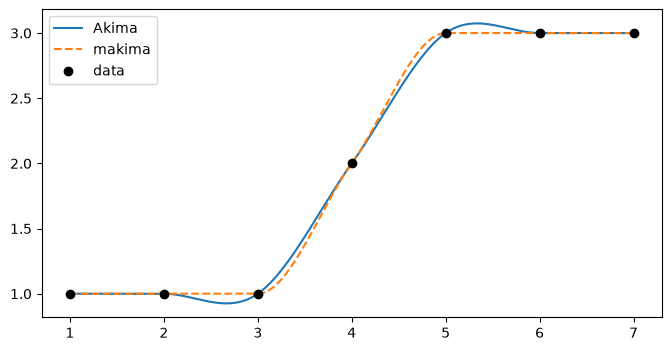

Akima   min = 0.9259   max = 3.0741
makima  min = 1.0000   max = 3.0000


In [4]:
x2 = np.array([1, 2, 3, 4, 5, 6, 7.])
y2 = np.array([1, 1, 1, 2, 3, 3, 3.])
xnew2 = np.linspace(1, 7, 601)

akima  = si.Akima1DInterpolator(x2, y2)
makima = si.Akima1DInterpolator(x2, y2, method="makima")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(xnew2, akima(xnew2), label="Akima")
ax.plot(xnew2, makima(xnew2), "--", label="makima")
ax.plot(x2, y2, "ko", label="data")
ax.legend()
plt.show()

for name, p in [("Akima", akima), ("makima", makima)]:
    v = p(xnew2)
    print(f"{name:7s} min = {v.min():.4f}   max = {v.max():.4f}")

- Akima dips below 1 and rises above 3, outside the data range.
- makima stays in $[1, 3]$. **If you use Akima, prefer `method="makima"`.**

## Example 3: accuracy on a smooth function

When the data come from a **smooth** function, we can measure the error. Sample $f(x) = \sin x$ on $[0, 2\pi]$ with $n$ equally spaced points
and compute the maximum error $\max |p(x) - f(x)|$ on a fine grid.

In [5]:
f = np.sin
xf = np.linspace(0, 2*np.pi, 2001)

print(f"{'n':>4s}" + "".join(f"{name:>14s}" for name in names))
for n in [6, 11, 21, 41]:
    xs = np.linspace(0, 2*np.pi, n)
    ys = f(xs)
    interps = [
        lambda xn: np.interp(xn, xs, ys),
        si.CubicSpline(xs, ys),
        si.Akima1DInterpolator(xs, ys),
        si.Akima1DInterpolator(xs, ys, method="makima"),
        si.PchipInterpolator(xs, ys),
    ]
    errs = [np.max(np.abs(p(xf) - f(xf))) for p in interps]
    print(f"{n:4d}" + "".join(f"{e:14.2e}" for e in errs))

   n        linear  cubic spline         Akima        makima         PCHIP
   6      1.82e-01      6.48e-02      7.21e-02      7.29e-02      1.12e-01
  11      4.89e-02      2.65e-03      1.55e-02      1.32e-02      4.89e-02
  21      1.22e-02      8.75e-05      1.98e-03      3.39e-03      3.62e-03
  41      3.07e-03      2.77e-06      2.48e-04      8.97e-04      9.11e-04


- For smooth data the **cubic spline is the most accurate**, and its error falls fastest as $n$ grows.
- Linear is the least accurate: doubling the points cuts its error by about 4, as in class ($O(h^2)$).
- There is a trade-off: the smoothest method is the most accurate on smooth data, while the local methods are safer on data with jumps or flat parts.

## Exercises

**Syntax for each method**

| method | build | evaluate |
|---|---|---|
| linear | (none) | `np.interp(xnew, x, y)` |
| cubic spline | `p = si.CubicSpline(x, y)` | `p(xnew)` |
| Akima | `p = si.Akima1DInterpolator(x, y)` | `p(xnew)` |
| modified Akima | `p = si.Akima1DInterpolator(x, y, method="makima")` | `p(xnew)` |
| PCHIP | `p = si.PchipInterpolator(x, y)` | `p(xnew)` |

<br><br>

| useful extra | call |
|---|---|
| $n$ equally spaced points on $[a, b]$ | `np.linspace(a, b, n)` |
| sample a function at those points | `xs = np.linspace(a, b, n); ys = f(xs)` |
| first derivative $p'$ (not for `np.interp`) | `p(xnew, 1)` |
| natural end conditions, $p'' = 0$ at both ends | `si.CubicSpline(x, y, bc_type="natural")` |
| one polynomial of degree $n$ through $n+1$ points | `coef = np.polyfit(x, y, n)`, then `np.polyval(coef, xnew)` |
| copy an array, then change element `i` to value `v` (indices start at 0) | `c2 = c.copy(); c2[i] = v` |

<br><br>

| checking a curve `v = p(xnew)` | call |
|---|---|
| smallest and largest value | `v.min()`, `v.max()` |
| maximum error against a known $f$ | `np.max(np.abs(v - f(xnew)))` |
| never decreasing? | `np.all(np.diff(v) >= 0)` |

<br><br>

| plotting | call |
|---|---|
| create a figure and axes | `fig, ax = plt.subplots()` |
| plot a curve with a label | `ax.plot(xnew, v, label="PCHIP")` |
| plot the data points | `ax.plot(x, y, "ko")` |
| horizontal line $y = c$ | `ax.axhline(c, color="k", lw=0.8)` |
| show the legend | `ax.legend()` |


**Exercise 1.** The Runge function $f(x) = \dfrac{1}{1 + 25x^2}$ on $[-1, 1]$.

(a) Sample $f$ at 11 equally spaced points. Interpolate with all five methods.
Evaluate the fitted curves on a **finer mesh** of 601 points, `xnew = np.linspace(-1, 1, 601)`, and plot them together with $f$.

(b) Print the maximum error $\max|p(x) - f(x)|$ for each method. Which method is the most accurate?

(c) Compare with **one polynomial of degree 10** through the same 11 points (Idea 2 from class):

```python
coef = np.polyfit(xs, ys, 10)   # the 11 coefficients, highest power first
v = np.polyval(coef, xnew)      # evaluate the polynomial at xnew
```

`np.polyfit(x, y, deg)` finds the polynomial of degree `deg` closest to the data.
With 11 points and degree 10 there are exactly as many coefficients as points, so the polynomial passes **through every point**: it is the interpolating polynomial.

Print its maximum error and plot it with the other methods. How do the piecewise methods compare, and why?

        linear  cubic spline         Akima        makima         PCHIP
      6.74e-02      2.20e-02      2.37e-02      1.95e-02      1.78e-02
PCHIP is the most accurate method.


TypeError: 'numpy.ndarray' object is not callable

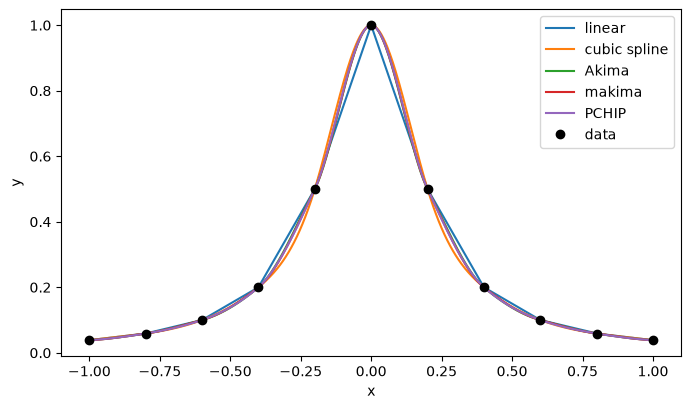

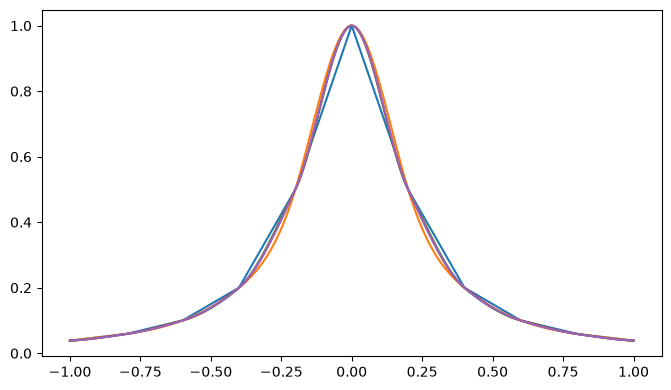

In [40]:
f = lambda xn: 1/(1 + 25*xn**2)
xs = np.linspace(-1, 1, 11)
y = 1/(1 + 25*xs**2)
xnew = np.linspace(-1, 1, 601)
names = ["linear", "cubic spline", "Akima", "makima", "PCHIP"]
meths = [
    lambda xn: np.interp(xn, xs, y),
    si.CubicSpline(xs, y),
    si.Akima1DInterpolator(xs, y),
    si.Akima1DInterpolator(xs, y, method="makima"),
    si.PchipInterpolator(xs, y),
]

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, p in zip(names, meths):
    ax.plot(xnew, p(xnew), label=name)
ax.plot(xs, y, "ko", label="data")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend()
plt.show

print("".join(f"{name:>14s}" for name in names))
errs = [np.max(np.abs(p(xnew) - f(xnew))) for p in meths]
print("".join(f"{e:14.2e}" for e in errs))
print("PCHIP is the most accurate method.")

coef = np.polyfit(xs, y, 10)
v = np.polyval(coef, xnew)

meths2 = [
    lambda xn: np.interp(xn, xs, y),
    si.CubicSpline(xs, y),
    si.Akima1DInterpolator(xs, y),
    si.Akima1DInterpolator(xs, y, method="makima"),
    si.PchipInterpolator(xs, y), coef,
]
names2 = ["linear", "cubic spline", "Akima", "makima", "PCHIP", "polyfit"] 

fig, ax = plt.subplots(figsize=(8, 4.5))
for name2, p in zip(names2, meths2):
    ax.plot(xnew, p(xnew), label=name2)
ax.plot(xs, y, "ko", label="data")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend()
plt.show

**Exercise 2.** A drug concentration $c$ (mg/L) is measured in the blood at times $t$ (hours):

```python
t = np.array([0, 1, 2, 4, 6, 8, 12, 24.])
c = np.array([0, 10, 8, 5, 3, 2, 1, 0.1])
```

(a) Interpolate with all five methods. Evaluate the fitted curves on a **finer mesh** of 601 points, `tnew = np.linspace(0, 24, 601)`, and plot them together with the data.

(b) For each method, print the **maximum of the fitted curve**, `p(tnew).max()` (for linear: `np.interp(tnew, t, c).max()`).
The highest measurement is 10 mg/L. Which methods predict a higher peak? Is that believable?

In [ ]:
# Exercise 2